# Avance — lectura, preparación y modelo base

Repositorio: https://github.com/jcdiegolopez/DS-LAB11

Destino: **Tikal y Flores (Petén)**. Variable: visitantes extranjeros únicos por subdestino y mes.
Se estiman enero y febrero de 2026, meses sin cobertura de telefonía, con un factor de reparto:

`estimación(subdestino, mes) = migración(mes) × factor(subdestino)`, con
`factor = Σ visitantes de movilidad / Σ entradas de migración (Turista + Excursionista)` en los meses observados.

El cuaderno ejecuta las etapas del pipeline (`reading`, `checks.runner`, `preparation`, `fitting`, `estimation`);
no contiene lógica propia más allá de mostrar los resultados.

In [1]:
import os
from pathlib import Path

if not Path("config.yaml").exists():
    os.chdir(Path.cwd().parent)

import pandas as pd
import matplotlib.pyplot as plt

from pipeline.config import load_config
from pipeline.run import execute
from pipeline.evaluation import baselines

pd.set_option("display.float_format", "{:,.1f}".format)
cfg = load_config("config.yaml")

## 1. Ejecución de las etapas del avance

La evaluación temporal y la publicación se incorporan en la entrega final.

In [2]:
STAGES = [
    ("read", "pipeline.stages.reading"),
    ("validate", "pipeline.checks.runner"),
    ("prepare", "pipeline.stages.preparation"),
    ("fit", "pipeline.stages.fitting"),
    ("estimate", "pipeline.stages.estimation"),
]
state = execute(cfg, STAGES)
print("run_id:", state.context.run_id)
print("status:", state.status.value, "| stages:", ", ".join(state.completed_stages))
print("source fingerprint:", state.source_fingerprint)

run_id: 20261029T230558Z-809c80
status: success | stages: read, validate, prepare, fit, estimate
source fingerprint: 9e3d5332f24d2bda27b4a2164ea891aa2907f6f96e869f5bf05b0de953aa096d


## 2. Controles de calidad

In [3]:
pd.DataFrame([{"check": r.name, "status": r.status.value, "detail": r.detail} for r in state.check_results])

,check,status,detail
0,columns_types,ok,all required columns present with compatible t...
1,dates_coverage,warning,"mobility: no coverage for 2026-01, 2026-02 (to..."
2,uniqueness,ok,"3473 rows, no duplicated keys"
3,missing_values,warning,"mobility: 8 null 'pais' (0.23%, limit 5.00%); ..."
4,values_denominators,warning,mobility: 8 rows with visitantes = 0 (8 in the...
5,methodology,ok,"monthly source, no aggregate rows, stay deriva..."


## 3. Series preparadas

Visitantes extranjeros por subdestino (sin sumar subdestinos). Enero y febrero de 2026 quedan vacíos, no en cero.

In [4]:
data = state.prepared
data.visitors

,Isla De Flores,El Remate Y Alrededores Lago,Mundo Maya Aeropuerto
period,,,
2025-09,"2,624.8","3,055.5","4,186.7"
2025-10,"3,564.3","3,804.6","5,250.6"
2025-11,"5,477.3","6,017.6","7,890.5"
2025-12,"5,408.6","6,232.2","8,069.3"
2026-01,NaN,NaN,NaN
2026-02,NaN,NaN,NaN
2026-03,"8,807.6","9,607.9","13,157.6"
2026-04,"7,539.5","7,885.8","11,708.7"
2026-05,"5,374.9","5,413.2","8,728.5"


In [5]:
data.migration.loc["2025-09":].to_frame()

,migration
period,
2025-09,"218,069.5"
2025-10,"255,920.9"
2025-11,"310,585.5"
2025-12,"365,573.0"
2026-01,"300,664.1"
2026-02,"236,844.1"
2026-03,"291,160.4"
2026-04,"260,951.0"
2026-05,"241,312.3"


## 4. Factor de reparto

In [6]:
model = state.model
print("method:", model.method, "| train months:", ", ".join(model.train_months))
model.factors.to_frame().style.format("{:.4f}")

method: ratio_of_sums | train months: 2025-09, 2025-10, 2025-11, 2025-12, 2026-03, 2026-04, 2026-05, 2026-06


,factor
Isla De Flores,0.0199
El Remate Y Alrededores Lago,0.0215
Mundo Maya Aeropuerto,0.0307


## 5. Estimaciones y referencias simples

Las referencias usan solo meses observados anteriores al mes estimado.

In [7]:
months = cfg.coverage.months_to_estimate
est = state.estimates
comparison = est[est["kind"] == "estimated"].pivot(index="period", columns="subdestination", values="value")
comparison = comparison[cfg.target.subdestinations]
tables = {"factor": comparison}
for name in cfg.evaluation.baselines:
    tables[name] = baselines.predict(name, data.visitors, months)
pd.concat(tables, axis=1).T

period                                      2026-01  2026-02
              subdestination                                
factor        Isla De Flores                5,998.1  4,724.9
              El Remate Y Alrededores Lago  6,467.8  5,094.9
              Mundo Maya Aeropuerto         9,221.4  7,264.0
last_observed Isla De Flores                5,408.6  5,408.6
              El Remate Y Alrededores Lago  6,232.2  6,232.2
              Mundo Maya Aeropuerto         8,069.3  8,069.3
prior_mean    Isla De Flores                4,268.8  4,268.8
              El Remate Y Alrededores Lago  4,777.5  4,777.5
              Mundo Maya Aeropuerto         6,349.3  6,349.3

In [8]:
est.head(12)

,target,subdestination,period,value,unit,kind,run_id,generated_at,procedure_version
0,Tikal y Flores (Petén),Isla De Flores,2025-09,"2,624.8",unique visitors per month,observed,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
1,Tikal y Flores (Petén),Isla De Flores,2025-10,"3,564.3",unique visitors per month,observed,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
2,Tikal y Flores (Petén),Isla De Flores,2025-11,"5,477.3",unique visitors per month,observed,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
3,Tikal y Flores (Petén),Isla De Flores,2025-12,"5,408.6",unique visitors per month,observed,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
4,Tikal y Flores (Petén),Isla De Flores,2026-01,"5,998.1",unique visitors per month,estimated,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
5,Tikal y Flores (Petén),Isla De Flores,2026-02,"4,724.9",unique visitors per month,estimated,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
6,Tikal y Flores (Petén),Isla De Flores,2026-03,"8,807.6",unique visitors per month,observed,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
7,Tikal y Flores (Petén),Isla De Flores,2026-04,"7,539.5",unique visitors per month,observed,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
8,Tikal y Flores (Petén),Isla De Flores,2026-05,"5,374.9",unique visitors per month,observed,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0
9,Tikal y Flores (Petén),Isla De Flores,2026-06,"4,877.3",unique visitors per month,observed,20261029T230558Z-809c80,2026-10-29T23:06:22+00:00,0.1.0


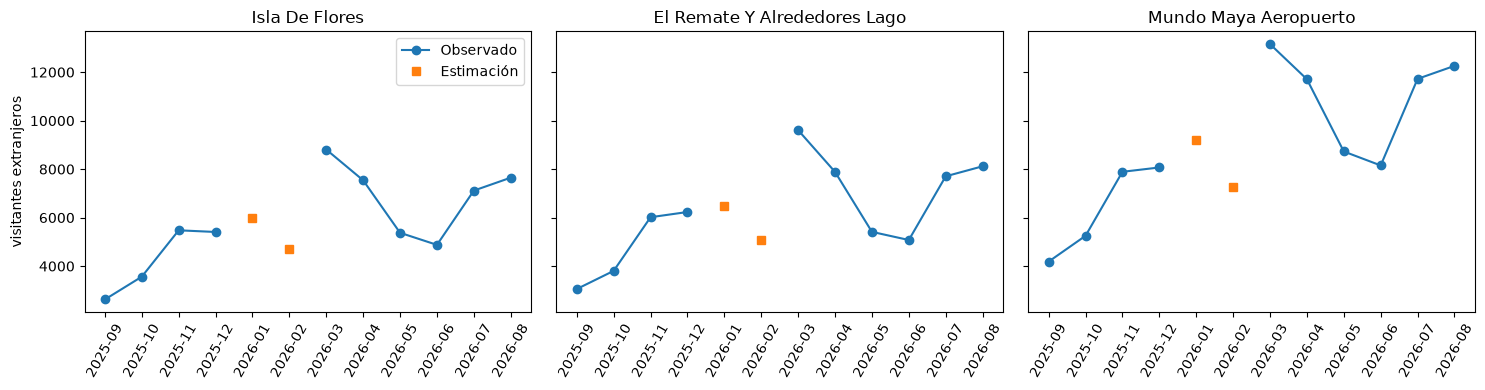

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, sub in zip(axes, cfg.target.subdestinations):
    observed = data.visitors[sub]
    ax.plot(observed.index, observed.values, marker="o", label="Observado")
    ax.plot(comparison.index, comparison[sub], marker="s", linestyle="none", color="tab:orange", label="Estimación")
    ax.set_title(sub)
    ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("visitantes extranjeros")
axes[0].legend()
plt.tight_layout()

## 6. Limitaciones

- Solo hay 8 meses con movilidad y migración a la vez para ajustar el factor (jul–ago 2026 no tienen migración).
- No se construye un total de Petén: los subdestinos comparten personas.
- El factor supone que la proporción de extranjeros captados por cada subdestino es estable entre meses;
  la validación temporal de la entrega final medirá qué tanto se cumple.